In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import plotly.express as px
import yaml
import sys
 
with open("../config.yaml", "r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

df_demo = pd.read_csv('../data/clean/df_demo_clean.csv')
df_roster = pd.read_csv('../data/clean/roster_clean.csv')
df_web = pd.read_csv('../data/clean/final_web_data_merged.csv')

In [2]:
df_demo


,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,836976,6,73,60.5,U,2,45105.30,6,9
1,2304905,7,94,58.0,U,2,110860.30,6,9
2,1439522,5,64,32.0,U,2,52467.79,6,9
3,1562045,16,198,49.0,M,2,67454.65,3,6
4,5126305,12,145,33.0,F,2,103671.75,0,3
...,...,...,...,...,...,...,...,...,...
70590,7993686,4,56,38.5,U,3,1411062.68,5,5
70591,8981690,12,148,31.0,M,2,101867.07,6,6
70592,333913,16,198,61.5,F,2,40745.00,3,3
70593,1573142,21,255,68.0,M,3,475114.69,4,4


In [3]:
df_roster


,client_id,variation
0,9988021,Test
1,8320017,Test
2,4033851,Control
3,1982004,Test
4,9294070,Control
...,...,...
50495,393005,Control
50496,2908510,Control
50497,7230446,Test
50498,5230357,Test


In [4]:
df_web

,client_id,visitor_id,visit_id,process_step,date_time
0,169,201385055_71273495308,749567106_99161211863_557568,start,2017-04-12 20:19:36
1,169,201385055_71273495308,749567106_99161211863_557568,step_1,2017-04-12 20:19:45
2,169,201385055_71273495308,749567106_99161211863_557568,step_2,2017-04-12 20:20:31
3,169,201385055_71273495308,749567106_99161211863_557568,step_3,2017-04-12 20:22:05
4,169,201385055_71273495308,749567106_99161211863_557568,confirm,2017-04-12 20:23:09
...,...,...,...,...,...
744636,9999875,738878760_1556639849,931268933_219402947_599432,step_1,2017-06-01 22:40:08
744637,9999875,738878760_1556639849,931268933_219402947_599432,step_1,2017-06-01 22:41:28
744638,9999875,738878760_1556639849,931268933_219402947_599432,step_2,2017-06-01 22:41:47
744639,9999875,738878760_1556639849,931268933_219402947_599432,step_3,2017-06-01 22:44:58


In [5]:
# Merging df_roster and df_demo on client_id, so the clients who were not part of the experiment are dropped
df_clients = pd.merge(df_roster, df_demo, on='client_id', how='inner')
df_clients

,client_id,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,9988021,Test,5,64,79.0,U,2,189023.86,1,4
1,8320017,Test,22,274,34.5,M,2,36001.90,5,8
2,4033851,Control,12,149,63.5,M,2,142642.26,5,8
3,1982004,Test,6,80,44.5,U,2,30231.76,1,4
4,9294070,Control,5,70,29.0,U,2,34254.54,0,3
...,...,...,...,...,...,...,...,...,...,...
50483,393005,Control,15,191,52.5,M,2,60344.67,1,4
50484,2908510,Control,21,252,34.0,M,3,141808.05,6,9
50485,7230446,Test,6,74,62.0,M,2,58778.11,2,5
50486,5230357,Test,23,278,30.5,M,2,61349.70,0,3


In [6]:
#checking for missing values
df_clients.isnull().sum()

client_id           0
variation           0
clnt_tenure_yr      0
clnt_tenure_mnth    0
clnt_age            0
gendr               0
num_accts           0
bal                 0
calls_6_mnth        0
logons_6_mnth       0
dtype: int64

In [7]:
final_merge = pd.merge(df_web, df_clients, on='client_id', how='inner')
final_merge

,client_id,visitor_id,visit_id,process_step,date_time,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,555,402506806_56087378777,637149525_38041617439_716659,start,2017-04-15 12:57:56,Test,3,46,29.5,U,2,25454.66,2,6
1,555,402506806_56087378777,637149525_38041617439_716659,step_1,2017-04-15 12:58:03,Test,3,46,29.5,U,2,25454.66,2,6
2,555,402506806_56087378777,637149525_38041617439_716659,step_2,2017-04-15 12:58:35,Test,3,46,29.5,U,2,25454.66,2,6
3,555,402506806_56087378777,637149525_38041617439_716659,step_3,2017-04-15 13:00:14,Test,3,46,29.5,U,2,25454.66,2,6
4,555,402506806_56087378777,637149525_38041617439_716659,confirm,2017-04-15 13:00:34,Test,3,46,29.5,U,2,25454.66,2,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317130,9999729,834634258_21862004160,870243567_56915814033_814203,confirm,2017-05-08 16:09:40,Test,10,124,31.0,F,3,107059.74,6,9
317131,9999729,604429154_69247391147,99583652_41711450505_426179,start,2017-04-05 13:40:49,Test,10,124,31.0,F,3,107059.74,6,9
317132,9999729,604429154_69247391147,99583652_41711450505_426179,step_1,2017-04-05 13:41:04,Test,10,124,31.0,F,3,107059.74,6,9
317133,9999832,145538019_54444341400,472154369_16714624241_585315,start,2017-05-16 16:46:03,Test,23,281,49.0,F,2,431887.61,1,4


In [8]:
final_merge['client_id'].nunique()

50488

In [9]:
# checking data types: date_time is a str
final_merge.info()

<class 'pandas.DataFrame'>
RangeIndex: 317135 entries, 0 to 317134
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   client_id         317135 non-null  int64  
 1   visitor_id        317135 non-null  str    
 2   visit_id          317135 non-null  str    
 3   process_step      317135 non-null  str    
 4   date_time         317135 non-null  str    
 5   variation         317135 non-null  str    
 6   clnt_tenure_yr    317135 non-null  int64  
 7   clnt_tenure_mnth  317135 non-null  int64  
 8   clnt_age          317135 non-null  float64
 9   gendr             317135 non-null  str    
 10  num_accts         317135 non-null  int64  
 11  bal               317135 non-null  float64
 12  calls_6_mnth      317135 non-null  int64  
 13  logons_6_mnth     317135 non-null  int64  
dtypes: float64(2), int64(6), str(6)
memory usage: 33.9 MB


In [10]:
#changing date_time to datetime type
final_merge["date_time"] = pd.to_datetime(final_merge["date_time"])
final_merge.info()


<class 'pandas.DataFrame'>
RangeIndex: 317135 entries, 0 to 317134
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   client_id         317135 non-null  int64         
 1   visitor_id        317135 non-null  str           
 2   visit_id          317135 non-null  str           
 3   process_step      317135 non-null  str           
 4   date_time         317135 non-null  datetime64[us]
 5   variation         317135 non-null  str           
 6   clnt_tenure_yr    317135 non-null  int64         
 7   clnt_tenure_mnth  317135 non-null  int64         
 8   clnt_age          317135 non-null  float64       
 9   gendr             317135 non-null  str           
 10  num_accts         317135 non-null  int64         
 11  bal               317135 non-null  float64       
 12  calls_6_mnth      317135 non-null  int64         
 13  logons_6_mnth     317135 non-null  int64         
dtypes: datetime64[u

In [11]:
final_merge.sort_values(["client_id", "visit_id", "date_time"])
final_merge.head(50)

,client_id,visitor_id,visit_id,process_step,date_time,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,555,402506806_56087378777,637149525_38041617439_716659,start,2017-04-15 12:57:56,Test,3,46,29.5,U,2,25454.66,2,6
1,555,402506806_56087378777,637149525_38041617439_716659,step_1,2017-04-15 12:58:03,Test,3,46,29.5,U,2,25454.66,2,6
2,555,402506806_56087378777,637149525_38041617439_716659,step_2,2017-04-15 12:58:35,Test,3,46,29.5,U,2,25454.66,2,6
3,555,402506806_56087378777,637149525_38041617439_716659,step_3,2017-04-15 13:00:14,Test,3,46,29.5,U,2,25454.66,2,6
4,555,402506806_56087378777,637149525_38041617439_716659,confirm,2017-04-15 13:00:34,Test,3,46,29.5,U,2,25454.66,2,6
5,647,66758770_53988066587,40369564_40101682850_311847,start,2017-04-12 15:41:28,Test,12,151,57.5,M,2,30525.80,0,4
6,647,66758770_53988066587,40369564_40101682850_311847,step_1,2017-04-12 15:41:35,Test,12,151,57.5,M,2,30525.80,0,4
7,647,66758770_53988066587,40369564_40101682850_311847,step_2,2017-04-12 15:41:53,Test,12,151,57.5,M,2,30525.80,0,4
8,647,66758770_53988066587,40369564_40101682850_311847,step_3,2017-04-12 15:45:02,Test,12,151,57.5,M,2,30525.80,0,4
9,647,66758770_53988066587,40369564_40101682850_311847,confirm,2017-04-12 15:47:45,Test,12,151,57.5,M,2,30525.80,0,4


In [12]:
df_events = pd.merge(df_web, df_roster, on="client_id", how="inner")
df_events

,client_id,visitor_id,visit_id,process_step,date_time,variation
0,555,402506806_56087378777,637149525_38041617439_716659,start,2017-04-15 12:57:56,Test
1,555,402506806_56087378777,637149525_38041617439_716659,step_1,2017-04-15 12:58:03,Test
2,555,402506806_56087378777,637149525_38041617439_716659,step_2,2017-04-15 12:58:35,Test
3,555,402506806_56087378777,637149525_38041617439_716659,step_3,2017-04-15 13:00:14,Test
4,555,402506806_56087378777,637149525_38041617439_716659,confirm,2017-04-15 13:00:34,Test
...,...,...,...,...,...,...
317230,9999729,834634258_21862004160,870243567_56915814033_814203,confirm,2017-05-08 16:09:40,Test
317231,9999729,604429154_69247391147,99583652_41711450505_426179,start,2017-04-05 13:40:49,Test
317232,9999729,604429154_69247391147,99583652_41711450505_426179,step_1,2017-04-05 13:41:04,Test
317233,9999832,145538019_54444341400,472154369_16714624241_585315,start,2017-05-16 16:46:03,Test


In [13]:
final_merge.to_csv(config["output_data"]["final_merge"], index=False)

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st

%matplotlib inline

### Hypotheses Test : Which high-balance clients call frequently but log in infrequently?

In [15]:
#Which high-balance clients call frequently but log in infrequently?
#Calculate the boundaries
#High balance: top 25%
# Many calls: top 25%
# Infrequent logins: bottom 25%


high_balance_limit = df_clients["bal"].quantile(0.75)
high_calls_limit = df_clients["calls_6_mnth"].quantile(0.75)
low_logons_limit = df_clients["logons_6_mnth"].quantile(0.25)

print("High-balance boundary:", high_balance_limit)
print("High-calls boundary:", high_calls_limit)
print("Low-logins boundary:", low_logons_limit)

High-balance boundary: 139956.54499999998
High-calls boundary: 5.0
Low-logins boundary: 4.0


In [16]:
#Filter the clients
high_value_phone_clients = df_clients[
    (df_clients["bal"] >= high_balance_limit) &
    (df_clients["calls_6_mnth"] >= high_calls_limit) &
    (df_clients["logons_6_mnth"] <= low_logons_limit)
].copy()

high_value_phone_clients.head()

,client_id,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth


In [17]:
print(
    "High-balance clients:",
    (df_clients["bal"] >= high_balance_limit).sum()
)


High-balance clients: 12622


In [18]:
print(
    "High-call clients:",
    (df_clients["calls_6_mnth"] >= high_calls_limit).sum()
)

High-call clients: 16932


In [19]:
print(
    "Low-login clients:",
    (df_clients["logons_6_mnth"] <= low_logons_limit).sum()
)

Low-login clients: 15166


In [20]:
print(
    "Clients meeting all conditions:",
    len(high_value_phone_clients)
)

Clients meeting all conditions: 0


In [21]:
#Filter using two requirements at a time
#High balance AND many calls:

high_balance_many_calls = df_clients[
    (df_clients["bal"] >= high_balance_limit) &
    (df_clients["calls_6_mnth"] >= high_calls_limit)
].copy()

In [22]:
#filter High balance AND few logins:
high_balance_few_logins = df_clients[
    (df_clients["bal"] >= high_balance_limit) &
    (df_clients["logons_6_mnth"] <= low_logons_limit)
].copy()

In [23]:
#Display the clients
columns = ["client_id", "bal", "calls_6_mnth", "logons_6_mnth"]

high_balance_many_calls[columns].sort_values("bal", ascending=False).head(20)

,client_id,bal,calls_6_mnth,logons_6_mnth
11956,9286288,16320040.15,6,9
22075,7070097,8986419.77,6,9
14677,9440656,8292996.21,6,9
41633,1678193,8137343.24,6,9
12552,6762377,8045102.60,6,9
7883,3519657,7741994.01,6,9
37125,857273,6716305.28,6,9
47053,9290030,6353000.43,5,8
50184,5735570,6000386.82,6,9
17508,3545814,5754204.68,6,9


In [24]:
#Display the clients
high_balance_few_logins[columns].sort_values("bal", ascending=False).head(20)

,client_id,bal,calls_6_mnth,logons_6_mnth
24697,2291985,8247729.97,1,4
24007,2686458,3647710.43,0,4
33928,6022010,3569381.23,1,4
4055,5902197,2739168.57,0,3
26926,1046182,2645921.89,1,4
11750,4039397,2612953.43,0,3
9557,1146418,2572758.49,0,4
47384,6650452,2543573.91,0,4
10545,4504614,2496867.17,1,4
8796,4281556,2433724.31,1,4


In [25]:
#Count them and calculate percentages
print("High balance + many calls:", len(high_balance_many_calls))
print("High balance + few logins:", len(high_balance_few_logins))

many_calls_pct = len(high_balance_many_calls) / len(df_clients) * 100
few_logins_pct = len(high_balance_few_logins) / len(df_clients) * 100

print(f"High balance + many calls: {many_calls_pct:.2f}% of all clients")
print(f"High balance + few logins: {few_logins_pct:.2f}% of all clients")

High balance + many calls: 6107
High balance + few logins: 2054
High balance + many calls: 12.10% of all clients
High balance + few logins: 4.07% of all clients


### Hypotheses Test : Which high-balance clients have the greatest relative reliance on customer-service calls?

In [26]:
#Which high-balance clients have the greatest relative reliance on customer-service calls?
#variable total interactions
df_clients["total_interactions"] = (
    df_clients["calls_6_mnth"] +
    df_clients["logons_6_mnth"]
)

In [27]:
#Calculate call share
df_clients["call_share"] = (
    df_clients["calls_6_mnth"] /
    df_clients["total_interactions"]
)

In [28]:
#Convert it to a percentage for easier reading
df_clients["call_share_percentage"] = (
    df_clients["call_share"] * 100
)

In [29]:
df_clients[
    [
        "calls_6_mnth",
        "logons_6_mnth",
        "total_interactions",
        "call_share_percentage"
    ]
].head()

,calls_6_mnth,logons_6_mnth,total_interactions,call_share_percentage
0,1,4,5,20.000000
1,5,8,13,38.461538
2,5,8,13,38.461538
3,1,4,5,20.000000
4,0,3,3,0.000000


In [30]:
#Define high-balance clients
#the top 25% as high-balance clients
high_balance_limit = df_clients["bal"].quantile(0.75)

print("High-balance boundary:", high_balance_limit)

High-balance boundary: 139956.54499999998


In [31]:
#Create a label
df_clients["balance_segment"] = np.where(
    df_clients["bal"] >= high_balance_limit,
    "High balance",
    "Other clients"
)

In [32]:
#Check the number of clients
df_clients["balance_segment"].value_counts()

balance_segment
Other clients    37866
High balance     12622
Name: count, dtype: int64

In [33]:
#Define high relative call usage
#the highest 25% of call_share as having high relative call usage
high_call_share_limit = (
    df_clients["call_share"].quantile(0.75)
)

print("High call-share boundary:", high_call_share_limit)

High call-share boundary: 0.38461538461538464


In [34]:
#Identify the target clients
phone_reliant_high_value_clients = df_clients[
    (df_clients["bal"] >= high_balance_limit) &
    (df_clients["call_share"] >= high_call_share_limit)
].copy()

In [35]:
print(
    "Number of high-balance, call-reliant clients:",
    len(phone_reliant_high_value_clients)
)

Number of high-balance, call-reliant clients: 6042


In [36]:
#Display the most valuable clients first
phone_reliant_high_value_clients[
    [
        "client_id",
        "bal",
        "calls_6_mnth",
        "logons_6_mnth",
        "call_share_percentage",
        "clnt_age",
        "clnt_tenure_yr",
        "num_accts"
    ]
].sort_values(
    "bal",
    ascending=False
).head(20)

,client_id,bal,calls_6_mnth,logons_6_mnth,call_share_percentage,clnt_age,clnt_tenure_yr,num_accts
11956,9286288,16320040.15,6,9,40.000000,62.5,21,3
22075,7070097,8986419.77,6,9,40.000000,53.0,11,2
14677,9440656,8292996.21,6,9,40.000000,63.0,7,2
41633,1678193,8137343.24,6,9,40.000000,65.5,24,3
12552,6762377,8045102.60,6,9,40.000000,41.5,16,3
7883,3519657,7741994.01,6,9,40.000000,66.5,18,6
37125,857273,6716305.28,6,9,40.000000,56.5,31,5
47053,9290030,6353000.43,5,8,38.461538,67.5,28,4
50184,5735570,6000386.82,6,9,40.000000,73.0,37,3
17508,3545814,5754204.68,6,9,40.000000,59.0,13,3


In [37]:
#Summarise the segment
segment_summary = pd.Series({
    "Number of clients": len(phone_reliant_high_value_clients),

    "Average balance":
        phone_reliant_high_value_clients["bal"].mean(),

    "Median balance":
        phone_reliant_high_value_clients["bal"].median(),

    "Average calls":
        phone_reliant_high_value_clients["calls_6_mnth"].mean(),

    "Average logins":
        phone_reliant_high_value_clients["logons_6_mnth"].mean(),

    "Average call share (%)":
        phone_reliant_high_value_clients[
            "call_share_percentage"
        ].mean(),

    "Average age":
        phone_reliant_high_value_clients["clnt_age"].mean(),

    "Average tenure":
        phone_reliant_high_value_clients[
            "clnt_tenure_yr"
        ].mean()
}).round(2)

segment_summary

Number of clients           6042.00
Average balance           475271.03
Median balance            295784.09
Average calls                  5.74
Average logins                 8.74
Average call share (%)        39.61
Average age                   55.28
Average tenure                15.02
dtype: float64

In [38]:
#Create a chart
#calculate the average call share for high-balance and other clients
call_share_summary = (
    df_clients
    .groupby("balance_segment")["call_share_percentage"]
    .mean()
    .reset_index()
)
call_share_summary

,balance_segment,call_share_percentage
0,High balance,32.134040
1,Other clients,26.293211


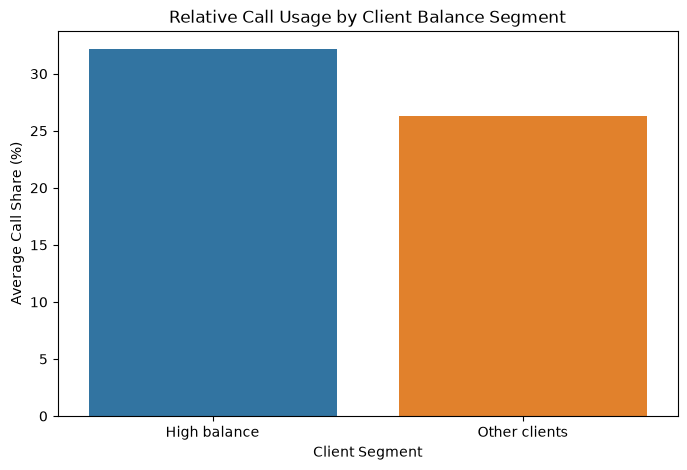

In [39]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=call_share_summary,
    x="balance_segment",
    y="call_share_percentage",
    hue="balance_segment",
    legend=False
)

plt.title("Relative Call Usage by Client Balance Segment")
plt.xlabel("Client Segment")
plt.ylabel("Average Call Share (%)")
plt.show()

In [40]:
#We want to test whether high-balance clients have a higher call share.

In [41]:
#Set hypotheses

# H0: Mean call share of high-balance clients
#     <= mean call share of other clients

# H1: Mean call share of high-balance clients
#     > mean call share of other clients

# The test statistic is expected to be positive when:
# mean_high_balance - mean_other_clients > 0

# Significance level = 0.05

In [42]:
#Set the significance level
alpha = 0.05

In [43]:
#Create the two samples
high_balance_call_share = df_clients[
    df_clients["balance_segment"] == "High balance"
]["call_share_percentage"]

other_clients_call_share = df_clients[
    df_clients["balance_segment"] == "Other clients"
]["call_share_percentage"]

In [44]:
#Examine the sample averages
print(
    "High-balance average call share:",
    high_balance_call_share.mean()
)

print(
    "Other clients' average call share:",
    other_clients_call_share.mean()
)

High-balance average call share: 32.13404005631862
Other clients' average call share: 26.29321127677173


In [45]:
statistic, p_value = st.ttest_ind(
    high_balance_call_share,
    other_clients_call_share,
    equal_var=False,
    alternative="greater"
)

statistic = float(statistic)
p_value = float(p_value)

print(f"Test statistic: {statistic:.4f}")
print(f"P-value: {p_value:.10e}")

Test statistic: 47.3386
P-value: 0.0000000000e+00


In [46]:
#Also check the sample sizes
n1 = len(high_balance_call_share)
n2 = len(other_clients_call_share)

print("High-balance sample size:", n1)
print("Other clients sample size:", n2)

n = n1 + n2 - 2

High-balance sample size: 12622
Other clients sample size: 37866


In [47]:
def show_statistical_test(statistic: float, alpha: float, n: int,
                          distribution: str = "normal", alternative: str = "two-sided"):
    if distribution not in ["t-student", "normal"]:
        raise TypeError("Only 't-student' and 'normal' are accepted")
    if alternative not in ["two-sided", "lower", "greater"]:
        raise TypeError("Only 'two-sided', 'lower' and 'greater' are accepted")
    if not isinstance(statistic, float) or not isinstance(alpha, float) or not isinstance(n, int):
        raise TypeError("statistic and alpha must be float, n must be int")

    d = st.norm() if distribution == "normal" else st.t(df=n - 1)
    x = np.linspace(-3, 3)
    fig = px.line(pd.DataFrame({"x": x, "pdf": d.pdf(x)}), x="x", y="pdf")

    def tail(a, b):  # red rejection area
        xs = np.linspace(a, b)
        fig.add_scatter(x=xs, y=d.pdf(xs), fill="tozeroy", mode="none", fillcolor="red")

    def label(x_pos, text, anchor):  # critical value line + label
        fig.add_vline(x=x_pos, line_color="red")
        fig.add_annotation(x=x_pos, y=0.08, text=text, xref="x", yref="paper",
                           xanchor=anchor, showarrow=False)

    if alternative == "two-sided":
        lo, hi = d.ppf(alpha / 2), d.ppf(1 - alpha / 2)
        tail(-3, lo); tail(hi, 3)
        label(lo, f"Lower critical value {lo:.2f}", "right")
        label(hi, f"Upper critical value {hi:.2f}", "left")
    elif alternative == "lower":
        c = d.ppf(alpha)
        tail(-3, c)
        label(c, f"Critical value {c:.2f}", "right")
    else:
        c = d.ppf(1 - alpha)
        tail(c, 3)
        label(c, f"Critical value {c:.2f}", "left")

    fig.add_vline(x=statistic)
    fig.add_annotation(x=statistic, y=1, text=f"Statistic {statistic:.2f}",
                       xref="x", yref="paper", yanchor="top", showarrow=False)

    fig.update_layout(title_text=f"{distribution} Probability Density Function",
                  title_x=0.5, showlegend=False,
                  height=380, width=750, margin=dict(t=50, b=40, l=40, r=20))
    fig.update_xaxes(range=[-max(4, abs(statistic) + 1), max(4, abs(statistic) + 1)])
    fig.show()

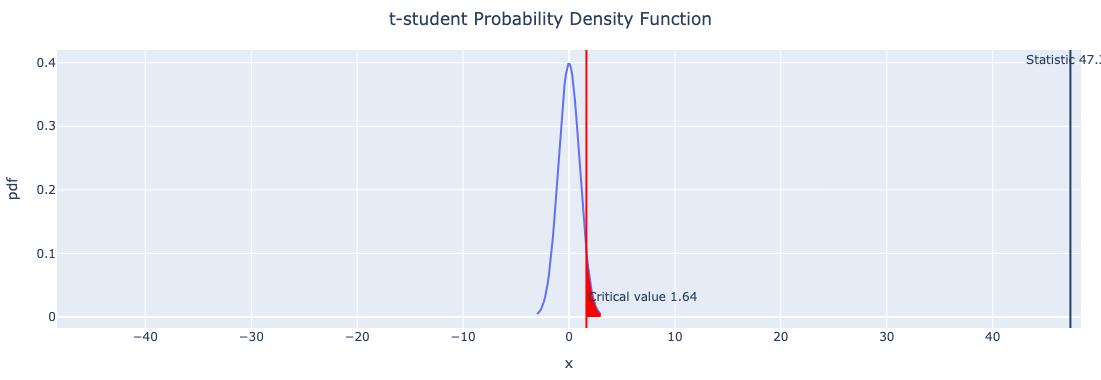

In [48]:
show_statistical_test(
    statistic=statistic,
    alpha=float(alpha),
    n=n,
    distribution="t-student",
    alternative="greater"
)

In [49]:
if p_value < alpha:
    print("We reject the null hypothesis.")
    print(
        "High-balance clients have significantly "
        "greater relative reliance on "
        "customer-service calls."
    )
else:
    print("We are not able to reject the null hypothesis.")
    print(
        "There is insufficient evidence that "
        "high-balance clients rely more heavily "
        "on customer-service calls."
    )

We reject the null hypothesis.
High-balance clients have significantly greater relative reliance on customer-service calls.


Another Analysis:
Do long-term clients maintain higher balances?


### Hypotheses test : Do long-term clients maintain higher balances?


In [50]:
#Create tenure groups

df_clients["tenure_group"] = pd.cut(
    df_clients["clnt_tenure_yr"],
    bins=[-1, 5, 10, float("inf")],
    labels=[
        "New (0–5 years)",
        "Established (6–10 years)",
        "Long-term (11+ years)"
    ]
)

In [51]:
#Calculate descriptive statistics
tenure_balance_summary = (
    df_clients
    .groupby("tenure_group", observed=False)
    .agg(
        number_of_clients=("client_id", "count"),
        average_balance=("bal", "mean"),
        median_balance=("bal", "median")
    )
    .round(2)
)

tenure_balance_summary

,number_of_clients,average_balance,median_balance
tenure_group,,,
New (0–5 years),8729,90266.64,46536.56
Established (6–10 years),15976,117428.23,60130.71
Long-term (11+ years),25783,189455.31,85509.23


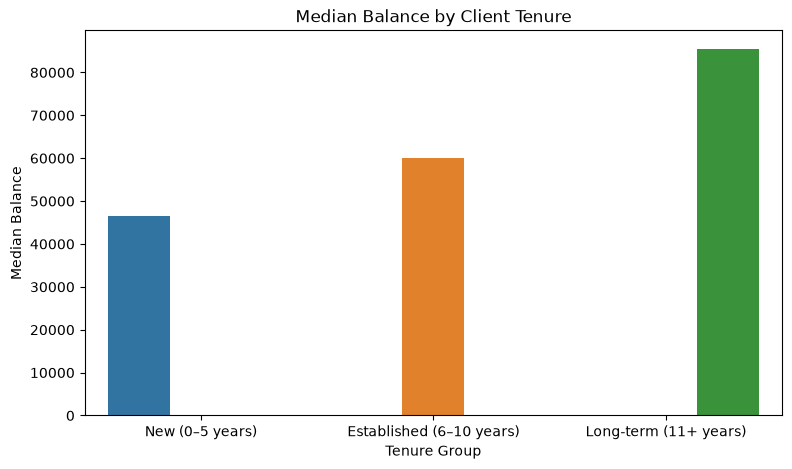

In [52]:
median_balance_plot = (
    df_clients
    .groupby("tenure_group", observed=False)["bal"]
    .median()
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=median_balance_plot,
    x="tenure_group",
    y="bal",
    hue="tenure_group",
    legend=False
)

plt.title("Median Balance by Client Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Median Balance")
plt.show()

In [53]:
# State the ANOVA hypotheses
# - H₀: All three tenure groups have the same average balance.
# - H₁: At least one tenure group has a different average balance

In [54]:
#Separate the groups
new_clients = df_clients[
    df_clients["tenure_group"] == "New (0–5 years)"
]["bal"]

established_clients = df_clients[
    df_clients["tenure_group"] == "Established (6–10 years)"
]["bal"]

long_term_clients = df_clients[
    df_clients["tenure_group"] == "Long-term (11+ years)"
]["bal"]

In [55]:
#Run ANOVA
anova_statistic, anova_p_value = st.f_oneway(
    new_clients,
    established_clients,
    long_term_clients
)

print("ANOVA statistic:", anova_statistic)
print(f"P-value: {anova_p_value:.3f}" )

ANOVA statistic: 492.94762521135874
P-value: 0.000


In [56]:
#Make the decision
alpha = 0.05

if anova_p_value < alpha:
    print("Reject the null hypothesis.")
    print("At least one tenure group has a different average balance.")
else:
    print("Do not reject the null hypothesis.")
    print("There is insufficient evidence of a balance difference.")

Reject the null hypothesis.
At least one tenure group has a different average balance.


### Hypotheses Test: Do Test clients experience fewer navigation errors?

In [57]:
#lets give each stage a number:
step_order = {
    "start": 0,
    "step_1": 1,
    "step_2": 2,
    "step_3": 3,
    "confirm": 4
}

final_merge["step_number"] = (
    final_merge["process_step"]
    .map(step_order)
)

In [58]:
final_merge[
    ["process_step", "step_number"]
].head(10)

,process_step,step_number
0,start,0
1,step_1,1
2,step_2,2
3,step_3,3
4,confirm,4
5,start,0
6,step_1,1
7,step_2,2
8,step_3,3
9,confirm,4


In [59]:
#Find the previous step
final_merge["previous_step"] = (
    final_merge
    .groupby("visit_id")["step_number"]
    .shift(1)
)

In [60]:
#Find backward movements
final_merge["backward_move"] = (
    final_merge["step_number"] <
    final_merge["previous_step"]
)

In [61]:
#True means a backward movement occurred.
final_merge["backward_move"].value_counts()

backward_move
False    291106
True      26029
Name: count, dtype: int64

In [62]:
#Find skipped stages
final_merge["skipped_stage"] = (
    final_merge["step_number"] -
    final_merge["previous_step"]
) > 1

In [63]:
#True means a stage was skipped.
final_merge["skipped_stage"].value_counts()

skipped_stage
False    315919
True       1216
Name: count, dtype: int64

In [64]:
#Find repeated stages
final_merge["repeated_stage"] = (
    final_merge["step_number"] ==
    final_merge["previous_step"]
)

In [65]:
#Calculate time between steps
final_merge["repeated_stage"].value_counts()

repeated_stage
False    284438
True      32697
Name: count, dtype: int64

In [66]:
#Calculate time between steps
final_merge["seconds_from_previous_step"] = (
    final_merge
    .groupby("visit_id")["date_time"]
    .diff()
    .dt.total_seconds()
)

In [67]:
final_merge[
    [
        "visit_id",
        "process_step",
        "date_time",
        "seconds_from_previous_step"
    ]
].head(10)

,visit_id,process_step,date_time,seconds_from_previous_step
0,637149525_38041617439_716659,start,2017-04-15 12:57:56,NaN
1,637149525_38041617439_716659,step_1,2017-04-15 12:58:03,7.0
2,637149525_38041617439_716659,step_2,2017-04-15 12:58:35,32.0
3,637149525_38041617439_716659,step_3,2017-04-15 13:00:14,99.0
4,637149525_38041617439_716659,confirm,2017-04-15 13:00:34,20.0
5,40369564_40101682850_311847,start,2017-04-12 15:41:28,NaN
6,40369564_40101682850_311847,step_1,2017-04-12 15:41:35,7.0
7,40369564_40101682850_311847,step_2,2017-04-12 15:41:53,18.0
8,40369564_40101682850_311847,step_3,2017-04-12 15:45:02,189.0
9,40369564_40101682850_311847,confirm,2017-04-12 15:47:45,163.0


In [68]:
#Define an unusually long step
Q1 = final_merge[
    "seconds_from_previous_step"
].quantile(0.25)

Q3 = final_merge[
    "seconds_from_previous_step"
].quantile(0.75)

IQR = Q3 - Q1

long_step_limit = Q3 + 1.5 * IQR

print("Long-step boundary:", long_step_limit)

Long-step boundary: 185.5


In [69]:
#long transitions:
final_merge["long_step"] = (
    final_merge["seconds_from_previous_step"] >
    long_step_limit
)
final_merge["long_step"]

0         False
1         False
2         False
3         False
4         False
          ...  
317130    False
317131    False
317132    False
317133    False
317134    False
Name: long_step, Length: 317135, dtype: bool

In [70]:
#Count confirmations per visit
final_merge["is_confirmation"] = (
    final_merge["process_step"] == "confirm"
)
final_merge["is_confirmation"]

0         False
1         False
2         False
3         False
4          True
          ...  
317130     True
317131    False
317132    False
317133    False
317134    False
Name: is_confirmation, Length: 317135, dtype: bool

In [71]:
# Summary of every website visit:
visit_summary = (
    final_merge
    .groupby("visit_id")
    .agg(
        client_id=("client_id", "first"),
        variation=("variation", "first"),
        start_time=("date_time", "min"),
        end_time=("date_time", "max"),
        event_count=("process_step", "count"),
        completed=("is_confirmation", "any"),
        confirmation_count=("is_confirmation", "sum"),
        backward_move=("backward_move", "any"),
        skipped_stage=("skipped_stage", "any"),
        repeated_stage=("repeated_stage", "any"),
        long_step=("long_step", "any")
    )
    .reset_index()
)
visit_summary

,visit_id,client_id,variation,start_time,end_time,event_count,completed,confirmation_count,backward_move,skipped_stage,repeated_stage,long_step
0,100012776_37918976071_457913,3561384,Test,2017-04-26 13:22:17,2017-04-26 13:23:09,2,True,2,False,False,True,False
1,100019538_17884295066_43909,7338123,Test,2017-04-09 16:20:56,2017-04-09 16:24:58,11,True,1,True,False,True,False
2,100022086_87870757897_149620,2478628,Test,2017-05-23 20:44:01,2017-05-23 20:47:01,5,True,1,False,False,False,False
3,100030127_47967100085_936361,105007,Control,2017-03-22 11:07:49,2017-03-22 11:07:49,1,False,0,False,False,False,False
4,100037962_47432393712_705583,5623007,Control,2017-04-14 16:41:51,2017-04-14 16:44:03,4,False,0,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
69180,999971096_28827267783_236076,2979920,Test,2017-04-13 10:31:49,2017-04-13 10:34:08,6,True,1,False,False,True,False
69181,999976049_95772503197_182554,4449968,Test,2017-04-04 12:50:10,2017-04-04 13:02:18,6,True,1,False,False,True,True
69182,999984454_18731538378_781808,829911,Test,2017-03-29 11:18:33,2017-03-29 11:21:07,5,True,1,False,False,False,False
69183,999985675_64610694964_443659,4064969,Control,2017-04-20 09:45:18,2017-04-20 10:02:48,5,True,1,False,False,False,True


In [72]:
#Identify multiple confirmations
visit_summary["multiple_confirms"] = (
    visit_summary["confirmation_count"] > 1
)

In [73]:
#navigation-error indicator
# A visit receives:
# True if at least one problem occurred
# False if none occurred

visit_summary["navigation_error"] = (
    visit_summary["backward_move"] |
    visit_summary["skipped_stage"] |
    visit_summary["repeated_stage"] |
    visit_summary["long_step"] |
    visit_summary["multiple_confirms"]
)
visit_summary["navigation_error"]

0         True
1         True
2        False
3        False
4         True
         ...  
69180     True
69181     True
69182    False
69183     True
69184     True
Name: navigation_error, Length: 69185, dtype: bool

In [74]:
#Compare Test and Control
error_summary = (
    visit_summary
    .groupby("variation")
    .agg(
        total_visits=("visit_id", "count"),
        visits_with_errors=("navigation_error", "sum"),
        error_rate=("navigation_error", "mean"),
        backward_rate=("backward_move", "mean"),
        skipped_rate=("skipped_stage", "mean"),
        repeated_rate=("repeated_stage", "mean"),
        long_step_rate=("long_step", "mean"),
        multiple_confirm_rate=("multiple_confirms", "mean")
    )
)

error_summary

,total_visits,visits_with_errors,error_rate,backward_rate,skipped_rate,repeated_rate,long_step_rate,multiple_confirm_rate
variation,,,,,,,,
Control,32122,14848,0.462238,0.204844,0.011519,0.249019,0.237096,0.026462
Test,37063,19065,0.514394,0.270755,0.020748,0.292286,0.247578,0.077247


In [75]:
#Convert the rates to percentages:
rate_columns = [
    "error_rate",
    "backward_rate",
    "skipped_rate",
    "repeated_rate",
    "long_step_rate",
    "multiple_confirm_rate"
]

error_summary[rate_columns] = (
    error_summary[rate_columns] * 100
)

error_summary.round(2)

,total_visits,visits_with_errors,error_rate,backward_rate,skipped_rate,repeated_rate,long_step_rate,multiple_confirm_rate
variation,,,,,,,,
Control,32122,14848,46.22,20.48,1.15,24.90,23.71,2.65
Test,37063,19065,51.44,27.08,2.07,29.23,24.76,7.72


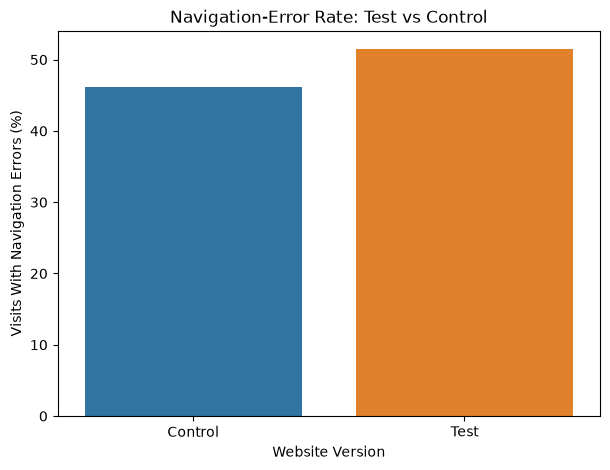

In [76]:
#Create a chart
error_plot = (
    visit_summary
    .groupby("variation")["navigation_error"]
    .mean()
    .mul(100)
    .reset_index()
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=error_plot,
    x="variation",
    y="navigation_error",
    hue="variation",
    legend=False
)

plt.title("Navigation-Error Rate: Test vs Control")
plt.xlabel("Website Version")
plt.ylabel("Visits With Navigation Errors (%)")
plt.show()

In [77]:
# Conduct a Chi-square test
# Hypotheses:
# H₀: Navigation errors are independent of website version.
# H₁: Navigation errors are associated with website version.

#Create the crosstab:
error_crosstab = pd.crosstab(
    visit_summary["variation"],
    visit_summary["navigation_error"]
)

error_crosstab

navigation_error,False,True
variation,,
Control,17274,14848
Test,17998,19065


In [78]:
#Run the test:
chi2, p_value, degrees_of_freedom, expected = (
    st.chi2_contingency(error_crosstab)
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

Chi-square statistic: 187.1090673563079
P-value: 1.3595151728084744e-42


In [79]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("Website version is associated with navigation errors.")
else:
    print("Do not reject the null hypothesis.")
    print("There is insufficient evidence of an association.")

Reject the null hypothesis.
Website version is associated with navigation errors.
